In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [33]:
df=pd.read_csv('car_fuel_efficiency_2026.csv')

In [34]:
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [35]:
df.columns

Index(['model_year', 'origin', 'fuel_type', 'drivetrain', 'num_doors',
       'engine_displacement', 'num_cylinders', 'horsepower', 'vehicle_weight',
       'acceleration', 'fuel_efficiency_mpg'],
      dtype='object')

In [36]:
#preparing data
df.columns=df.columns.str.lower().str.replace(' ','_')

In [37]:

base=['engine_displacement','horsepower','vehicle_weight','model_year','fuel_efficiency_mpg']
df=df[base]


<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

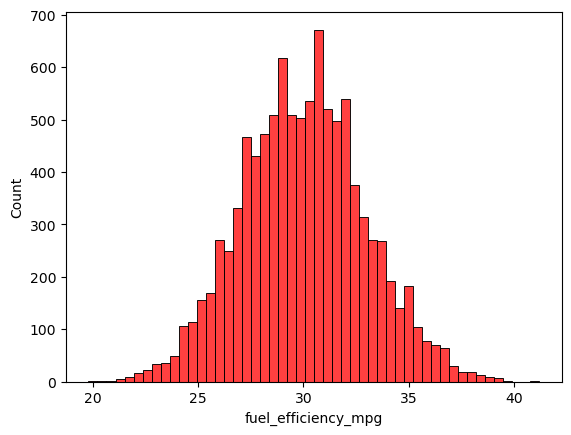

In [38]:
sns.histplot(df.fuel_efficiency_mpg,color='red', bins=50)

<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

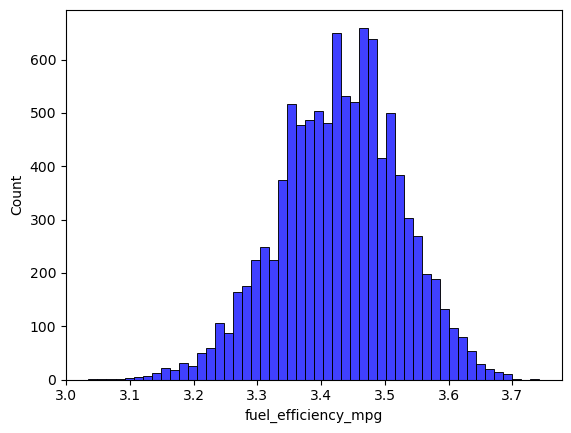

In [39]:
sns.histplot(np.log1p(df.fuel_efficiency_mpg),color='blue', bins=50)

In [40]:
df.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

In [41]:
#Question 2

df.horsepower.median()

254.0

In [42]:
#question 3
n=len(df)
n_val=int(n * 0.2)
n_test=int(n * 0.2)
n_train=n-n_val-n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train =df.iloc[idx[:n_train]]
df_val =df.iloc[idx[n_train:n_train + n_val]]
df_test =df.iloc[idx[n_train + n_val:]]

In [43]:
y_train=df_train.fuel_efficiency_mpg.values
y_val=df_val.fuel_efficiency_mpg.values
y_test=df_test.fuel_efficiency_mpg.values

In [44]:
del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [45]:
#case de 0:
def prepare_x_0(df):
    df=df.copy()
    
    df_pre=df.fillna(0)
    X_pre=df_pre.values
    return X_pre
    

In [46]:
def prepare_x_mean(df):
    df=df.copy()
    
    df_pre=df.fillna(df.mean())
    X_pre=df_pre.values
    return X_pre

In [47]:
def train_linear_regression(X,y):
    ones=np.ones(X.shape[0])
    X=np.column_stack([ones,X])
    
    XTX=X.T.dot(X)
    XTX_inv=np.linalg.inv(XTX)
    w_full=XTX_inv.dot(X.T).dot(y)
    
    w0=w_full[0]
    w=w_full[1:]
    return w0,w
    

In [48]:
def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)
    

In [49]:
X_train_0=prepare_x_0(df_train)
w0,w=train_linear_regression(X_train_0,y_train)
X_val=prepare_x_0(df_val)
y_pred_0=w0+X_val.dot(w)
score_0=round(rmse(y_val,y_pred_0),3)


X_train_mean=prepare_x_mean(df_train)
w0,w=train_linear_regression(X_train_mean,y_train)
X_val=prepare_x_mean(df_val)
y_pred_mean=w0+X_val.dot(w)
score_mean=round(rmse(y_val,y_pred_mean),3)

print(score_0,score_mean)


2.205 2.202


In [50]:
score_mean<score_0

np.True_

In [51]:
#Question 4
def prepare_x_mean(df):
    df=df.copy()
    
    df_pre=df.fillna(df.mean())
    X_pre=df_pre.values
    return X_pre

In [52]:
def train_linear_regression_reg(X,y,r):
    ones=np.ones(X.shape[0])
    X=np.column_stack([ones,X])
    
    XTX=X.T.dot(X)
    XTX=XTX+r*np.eye(XTX.shape[0])
    XTX_inv=np.linalg.inv(XTX)
    w_full=XTX_inv.dot(X.T).dot(y)
    
    w0=w_full[0]
    w=w_full[1:]
    return w0,w

In [53]:
r=[0, 0.01, 0.1, 1, 5, 10, 100]
for v in r:
    X_train_0=prepare_x_0(df_train)
    w0,w=train_linear_regression_reg(X_train_0,y_train,v)
    X_val=prepare_x_0(df_val)
    y_pred_0=w0+X_val.dot(w)
    score_0=round(rmse(y_val,y_pred_0),4)
    print(v,score_0)
    

0 2.2053
0.01 2.2058
0.1 2.2241
1 2.3492
5 2.4094
10 2.4195
100 2.4292


In [57]:
#question 5
values=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
rmse_scores=[] 
for v in values:
    #question 3
    
    #For each seed, do the train/validation/test split with 60%/20%/20% distribution
    n=len(df)
    n_val=int(n * 0.2)
    n_test=int(n * 0.2)
    n_train=n-n_val-n_test

    np.random.seed(v)
    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train =df.iloc[idx[:n_train]]
    df_val =df.iloc[idx[n_train:n_train + n_val]]
    df_test =df.iloc[idx[n_train + n_val:]]
    
    y_train=df_train.fuel_efficiency_mpg.values
    y_val=df_val.fuel_efficiency_mpg.values
    y_test=df_test.fuel_efficiency_mpg.values   
    
    del df_train['fuel_efficiency_mpg']
    del df_val['fuel_efficiency_mpg']
    del df_test['fuel_efficiency_mpg']
    

   
    
    #Fill the missing values with 0 and train a model without regularization
    X_train_0=prepare_x_0(df_train)
    #For each seed, evaluate the model on the validation dataset and collect the RMSE scores
    w0,w=train_linear_regression(X_train_0,y_train)
    X_val=prepare_x_0(df_val)
    y_pred_0=w0+X_val.dot(w)
    score_0=round(rmse(y_val,y_pred_0),3)
    #print(score_0)
    
    rmse_scores.append(score_0)
    #What's the standard deviation of all the scores? To compute the standard deviation, use np.std.
    #Round the result to 3 decimal digits (round(std, 3))
print(round(np.std(rmse_scores),3))

0.029


In [58]:
#question6
n=len(df)
n_val=int(n * 0.2)
n_test=int(n * 0.2)
n_train=n-n_val-n_test

np.random.seed(9)
idx = np.arange(n)
np.random.shuffle(idx)

df_train =df.iloc[idx[:n_train]]
df_val =df.iloc[idx[n_train:n_train + n_val]]
df_test =df.iloc[idx[n_train + n_val:]]

y_train=df_train.fuel_efficiency_mpg.values
y_val=df_val.fuel_efficiency_mpg.values
y_test=df_test.fuel_efficiency_mpg.values   
    
del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']



df_full=pd.concat([df_train,df_val])
y_full=np.concatenate([y_train,y_val])

X_full_0=prepare_x_0(df_full)
w0,w=train_linear_regression_reg(X_full_0,y_full,0.001)

X_test=prepare_x_0(df_test)
y_pred_0=w0+X_test.dot(w)
round(rmse(y_test,y_pred_0),3)


np.float64(2.236)